# Boss Gauntlet: Deep Reinforcement Learning Evaluation
**Course:** Reinforcement Learning and Optimal Control (2026/2027)  
**Program:** 3CS – Artificial Intelligence & Data Science  
**Instructors:** N. Farhi & M. Bouali  
**Project:** Development of a Game-Based Environment for Reinforcement Learning — *30 Bloodsheds: Boss Gauntlet*

---

## 1. Project & Environment Overview
The objective of this project is to develop an interactive 2D boss battle environment and train autonomous agents to master combat mechanics using Deep Reinforcement Learning (DRL).

### Key System Specifications & Environment
- **Environment**: Custom 2D Gymnasium environment (`BossFightEnv`) with symplectic Euler physics (60 FPS tick, 4-frame skip $\Delta t = 1/15$s).
- **Markov Decision Process (MDP)**:
  - **Observation Space**: Continuous $\mathcal{S} \subset \mathbb{R}^{52}$, consisting of normalized spatial kinematic features (player/boss position, velocity, distances), cooldown/cast timers, hazard tracking (spikes, projectile, dark wave), and one-hot encoded state/attack indicators.
  - **Action Space**: Discrete $\mathcal{A} = \{0, \dots, 9\}$ with **Action Masking** (Move Left, Move Right, Jump, Light Attack, Heavy Attack, Roll/Dodge, Parry/Block, Super Move, Heal Flask, Idle).
  - **Reward Function**: Dense potential-based shaping for dealing boss damage, defensive execution (successful parries, dodging attacks), with penalties for receiving damage, stamina depletion, and time elapsed.
- **DRL Algorithm**: **MaskablePPO** (Proximal Policy Optimization with invalid action masking via `sb3-contrib`).
- **Neural Network Architecture**: Custom 4-stream feature extractor (`BossGauntletFeaturesExtractor`) separating Player, Boss, Hazard, and Context state streams into a shared fusion representation.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Visual theme setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

print("Environment libraries loaded successfully.")


Environment libraries loaded successfully.


---
## 2. Training Convergence Analysis
As required by the project specifications:
- Training convergence is analyzed using the **total undiscounted episode return** (not discounted return).
- The raw episode rewards and lengths are logged using Stable-Baselines3 `Monitor` wrapper and exported to TensorBoard.
- A **sliding window moving average** (window = 30 episodes) is applied to expose learning trends amidst high episode variance.


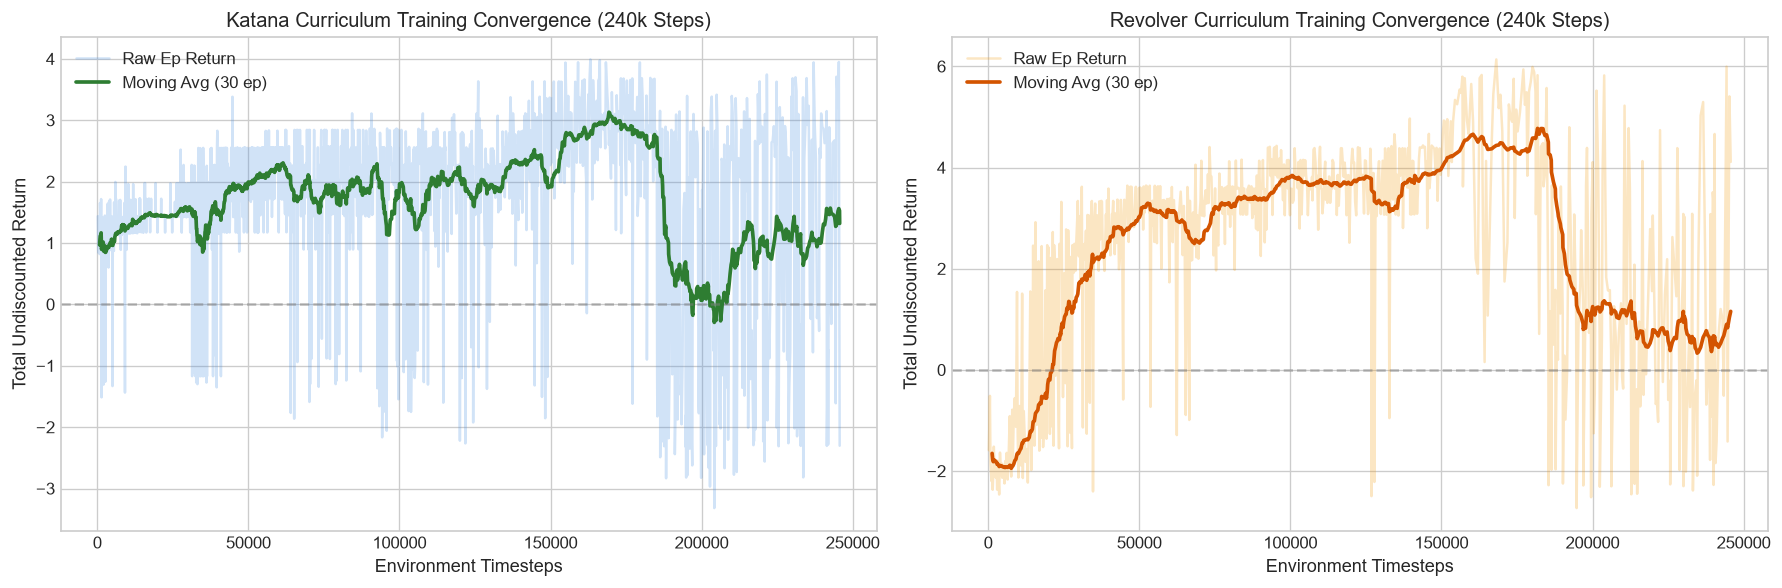

In [2]:
# Locate monitor logs
katana_monitor = "runs/katana_curriculum_1790962011/monitor_katana.monitor.csv"
revolver_monitor = "runs/revolver_curriculum_1791203626/monitor_revolver.monitor.csv"

def load_monitor(path):
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path, skiprows=1)
    df["cumulative_steps"] = df["l"].cumsum()
    df["rolling_reward"] = df["r"].rolling(window=30, min_periods=5).mean()
    df["rolling_length"] = df["l"].rolling(window=30, min_periods=5).mean()
    return df

df_k = load_monitor(katana_monitor)
df_r = load_monitor(revolver_monitor)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot Katana Convergence
if df_k is not None:
    ax1.plot(df_k["cumulative_steps"], df_k["r"], color="#4a90e2", alpha=0.25, label="Raw Ep Return")
    ax1.plot(df_k["cumulative_steps"], df_k["rolling_reward"], color="#2e7d32", linewidth=2.2, label="Moving Avg (30 ep)")
    ax1.axhline(0.0, color="gray", linestyle="--", alpha=0.5)
    ax1.set_title("Katana Curriculum Training Convergence (240k Steps)")
    ax1.set_xlabel("Environment Timesteps")
    ax1.set_ylabel("Total Undiscounted Return")
    ax1.legend(loc="upper left")

# Plot Revolver Convergence
if df_r is not None:
    ax2.plot(df_r["cumulative_steps"], df_r["r"], color="#f39c12", alpha=0.25, label="Raw Ep Return")
    ax2.plot(df_r["cumulative_steps"], df_r["rolling_reward"], color="#d35400", linewidth=2.2, label="Moving Avg (30 ep)")
    ax2.axhline(0.0, color="gray", linestyle="--", alpha=0.5)
    ax2.set_title("Revolver Curriculum Training Convergence (240k Steps)")
    ax2.set_xlabel("Environment Timesteps")
    ax2.set_ylabel("Total Undiscounted Return")
    ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()


---
## 3. Evaluation Metrics Justification
To rigorously evaluate the trained RL agent against the rule-based baseline agent across the gauntlet, multiple evaluation metrics were selected:

1. **Win Rate (%)**:
   - *Justification*: The ultimate success criterion of the task. Measures whether the agent achieves the primary terminal objective (reducing the boss's HP to 0 before dying or timing out).
2. **Mean Undiscounted Return**:
   - *Justification*: Reflects the overall behavioral quality and policy optimality according to the MDP reward formulation, incorporating damage efficiency, parry execution, and damage avoidance.
3. **Mean Hearts Lost**:
   - *Justification*: Measures defensive execution precision and survivability. In later gauntlet fights with lethal multi-hit attacks, lower hearts lost directly indicates successful timing of rolls and parries.
4. **Mean Fight Duration (Seconds)**:
   - *Justification*: Measures the agent's combat pacing and aggressiveness. Shorter fights with high win rates indicate high damage per second (DPS) and decisive exploitation of punish windows.
5. **Mean Damage Dealt**:
   - *Justification*: Tracks agent offensive capability even in fights where it was defeated, distinguishing near-misses from rapid losses.


In [3]:
katana_csv = "results/eval_report_1790962623.csv"
revolver_csv = "results/eval_report_1791204312.csv"

df_katana_eval = pd.read_csv(katana_csv)
df_revolver_eval = pd.read_csv(revolver_csv)

print("=== KATANA BENCHMARK RESULTS (15 Episodes per Fight Stage) ===")
display(df_katana_eval[["fight", "agent", "win_rate", "mean_reward", "mean_hearts_lost", "mean_duration_s", "mean_damage"]])

print("\n=== REVOLVER BENCHMARK RESULTS (15 Episodes per Fight Stage) ===")
display(df_revolver_eval[["fight", "agent", "win_rate", "mean_reward", "mean_hearts_lost", "mean_duration_s", "mean_damage"]])


=== KATANA BENCHMARK RESULTS (15 Episodes per Fight Stage) ===


,fight,agent,win_rate,mean_reward,mean_hearts_lost,mean_duration_s,mean_damage
0,1,Rule-Based,100.000000,1.722000,2.000000,5.183333,150.000000
1,1,MaskablePPO,100.000000,2.816000,0.000000,5.550000,150.000000
2,4,Rule-Based,100.000000,1.615333,2.333333,6.738889,193.000000
3,4,MaskablePPO,100.000000,2.725333,0.333333,6.038889,193.000000
4,8,Rule-Based,0.000000,-1.160867,5.066667,8.375556,238.000000
5,8,MaskablePPO,100.000000,2.836800,0.800000,9.525556,250.000000
6,12,Rule-Based,20.000000,-0.781900,5.000000,9.938889,238.733333
7,12,MaskablePPO,86.666667,2.347110,2.066667,12.612222,294.733333
8,16,Rule-Based,0.000000,-1.428579,5.133333,9.012222,224.000000
9,16,MaskablePPO,100.000000,3.412467,1.000000,13.123333,367.000000



=== REVOLVER BENCHMARK RESULTS (15 Episodes per Fight Stage) ===


,fight,agent,win_rate,mean_reward,mean_hearts_lost,mean_duration_s,mean_damage
0,1,Rule-Based,100.000000,1.702000,4.000000,13.150000,150.000000
1,1,MaskablePPO,100.000000,3.340000,0.000000,10.616667,150.000000
2,4,Rule-Based,100.000000,1.978667,3.333333,12.488889,193.000000
3,4,MaskablePPO,100.000000,3.631667,0.000000,11.172222,193.000000
4,8,Rule-Based,60.000000,0.462467,4.200000,16.265556,189.200000
5,8,MaskablePPO,93.333333,5.138400,1.400000,34.545556,240.133333
6,12,Rule-Based,60.000000,0.963060,4.333333,22.796667,260.600000
7,12,MaskablePPO,80.000000,5.135037,1.466667,39.551111,268.800000
8,16,Rule-Based,13.333333,-1.270841,6.400000,15.682222,182.800000
9,16,MaskablePPO,93.333333,5.663617,2.733333,36.917778,357.733333


---
## 4. Benchmark Visualizations: RL vs. Rule-Based Baseline
Below we visualize the comparative performance of the **MaskablePPO** policy against the **Rule-Based Agent** across all evaluated gauntlet stages (F1 through F30).


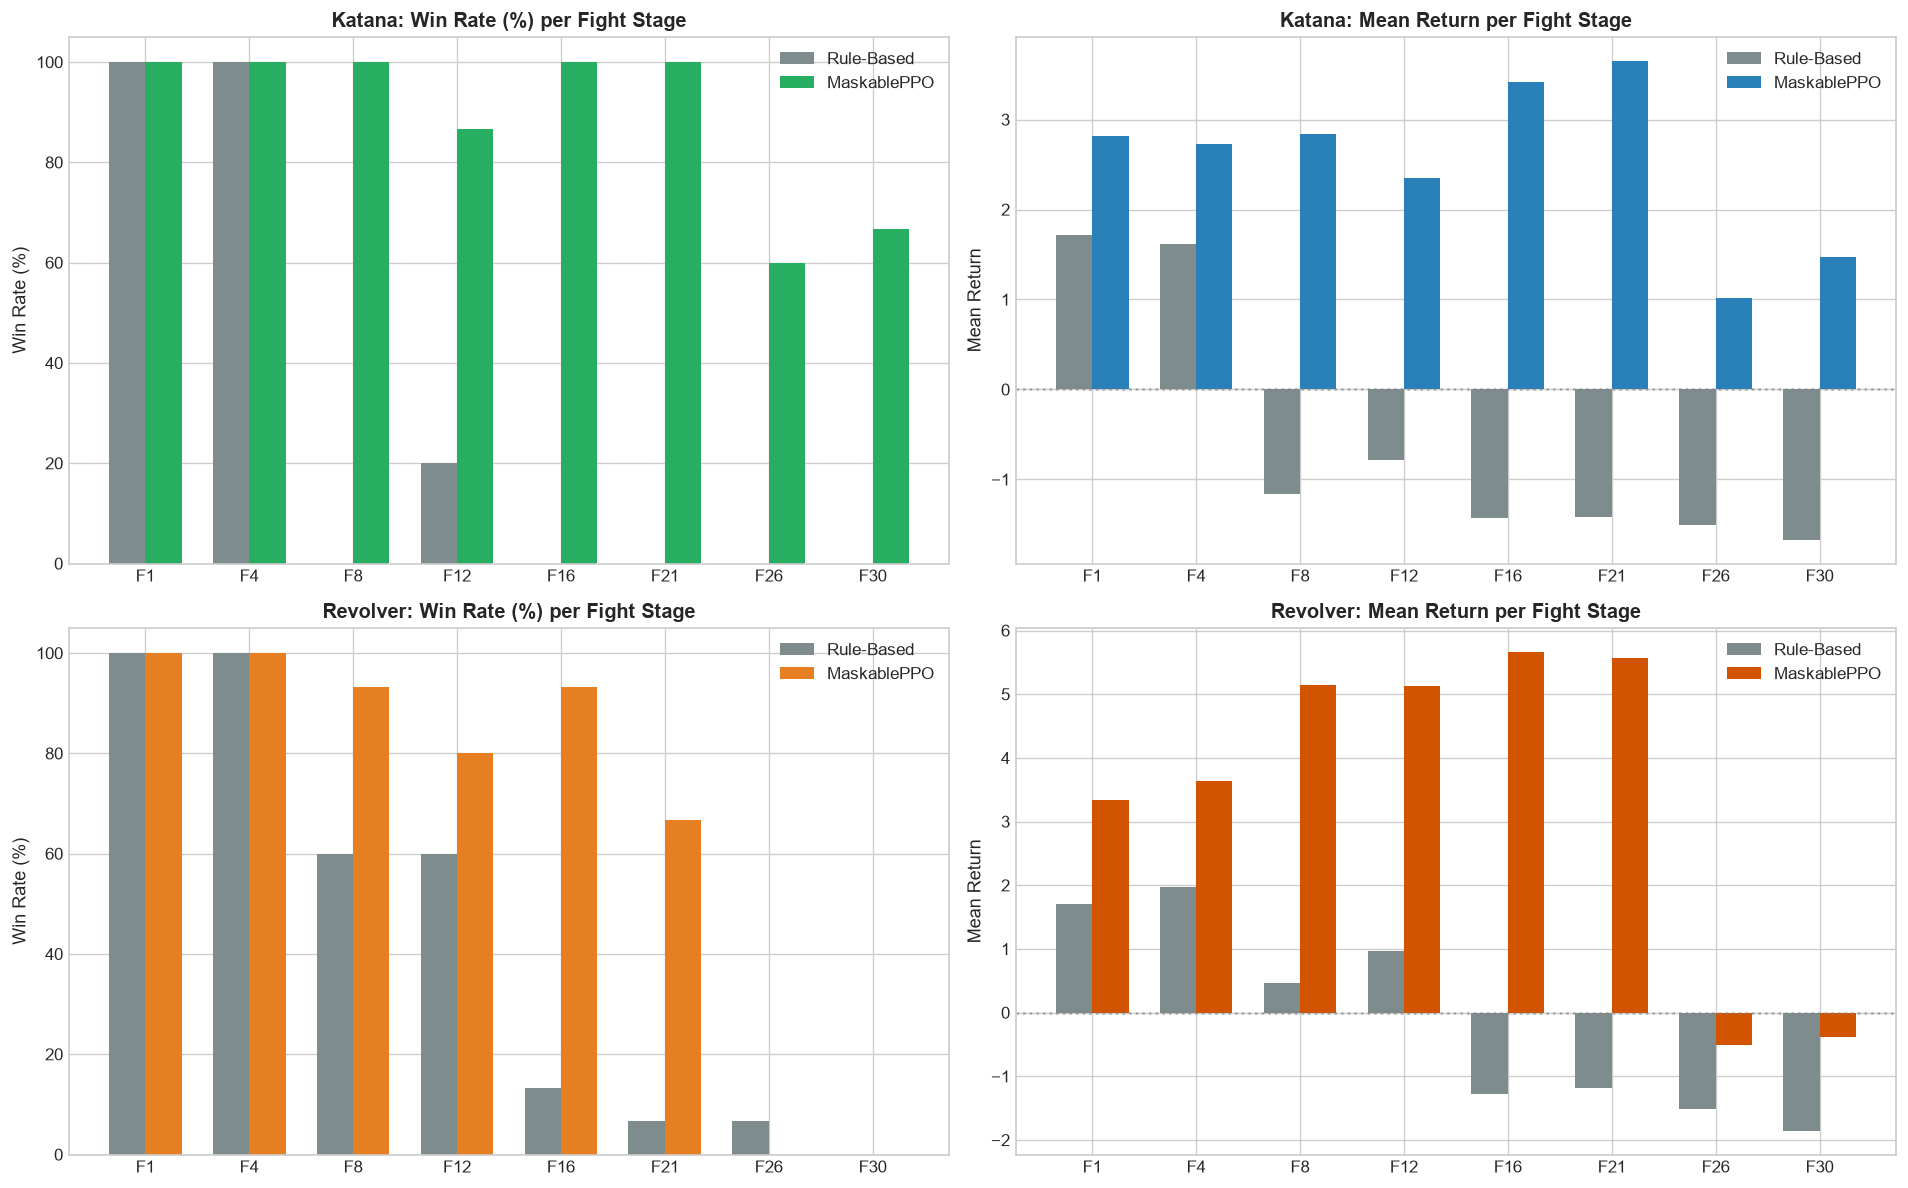

In [4]:
fights = sorted(df_katana_eval["fight"].unique())
x = np.arange(len(fights))
width = 0.35

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Katana Win Rate
ax = axes[0, 0]
k_rule_win = df_katana_eval[df_katana_eval["agent"] == "Rule-Based"].sort_values("fight")["win_rate"]
k_rl_win = df_katana_eval[df_katana_eval["agent"] == "MaskablePPO"].sort_values("fight")["win_rate"]
ax.bar(x - width/2, k_rule_win, width, label="Rule-Based", color="#7f8c8d")
ax.bar(x + width/2, k_rl_win, width, label="MaskablePPO", color="#27ae60")
ax.set_title("Katana: Win Rate (%) per Fight Stage", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Win Rate (%)")
ax.set_ylim(0, 105)
ax.legend()

# 2. Katana Mean Return
ax = axes[0, 1]
k_rule_rew = df_katana_eval[df_katana_eval["agent"] == "Rule-Based"].sort_values("fight")["mean_reward"]
k_rl_rew = df_katana_eval[df_katana_eval["agent"] == "MaskablePPO"].sort_values("fight")["mean_reward"]
ax.bar(x - width/2, k_rule_rew, width, label="Rule-Based", color="#7f8c8d")
ax.bar(x + width/2, k_rl_rew, width, label="MaskablePPO", color="#2980b9")
ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
ax.set_title("Katana: Mean Return per Fight Stage", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Mean Return")
ax.legend()

# 3. Revolver Win Rate
ax = axes[1, 0]
r_rule_win = df_revolver_eval[df_revolver_eval["agent"] == "Rule-Based"].sort_values("fight")["win_rate"]
r_rl_win = df_revolver_eval[df_revolver_eval["agent"] == "MaskablePPO"].sort_values("fight")["win_rate"]
ax.bar(x - width/2, r_rule_win, width, label="Rule-Based", color="#7f8c8d")
ax.bar(x + width/2, r_rl_win, width, label="MaskablePPO", color="#e67e22")
ax.set_title("Revolver: Win Rate (%) per Fight Stage", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Win Rate (%)")
ax.set_ylim(0, 105)
ax.legend()

# 4. Revolver Mean Return
ax = axes[1, 1]
r_rule_rew = df_revolver_eval[df_revolver_eval["agent"] == "Rule-Based"].sort_values("fight")["mean_reward"]
r_rl_rew = df_revolver_eval[df_revolver_eval["agent"] == "MaskablePPO"].sort_values("fight")["mean_reward"]
ax.bar(x - width/2, r_rule_rew, width, label="Rule-Based", color="#7f8c8d")
ax.bar(x + width/2, r_rl_rew, width, label="MaskablePPO", color="#d35400")
ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
ax.set_title("Revolver: Mean Return per Fight Stage", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Mean Return")
ax.legend()

plt.tight_layout()
plt.show()


---
## 5. Cross-Weapon Comparison: Katana vs. Revolver RL Policies
A direct comparison between the two learned policies highlights how weapon mechanics impact the agent's strategy:
- **Katana**: High risk, high reward melee. Requires staying in close quarters, precise parry timing, and immediate punish swings.
- **Revolver**: Ranged kiting with ammunition management (6 rounds, reload timer). Highly safe in early/mid stages, but vulnerable to reload vulnerability windows when the boss applies multi-hazard pressure.


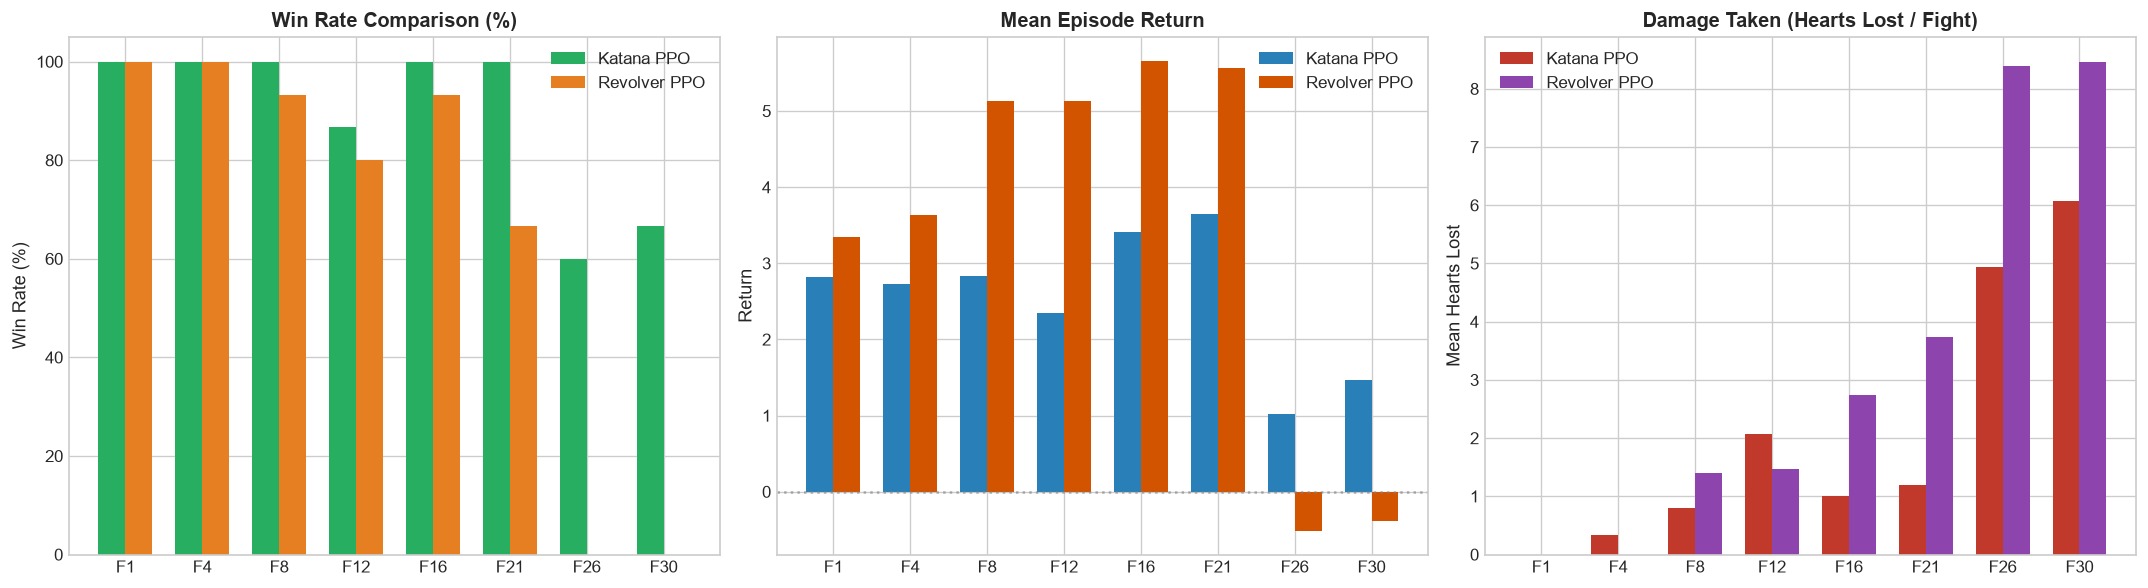

In [5]:
dk = df_katana_eval[df_katana_eval["agent"] == "MaskablePPO"].sort_values("fight")
dr = df_revolver_eval[df_revolver_eval["agent"] == "MaskablePPO"].sort_values("fight")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Win Rate
ax = axes[0]
ax.bar(x - width/2, dk["win_rate"], width, label="Katana PPO", color="#27ae60")
ax.bar(x + width/2, dr["win_rate"], width, label="Revolver PPO", color="#e67e22")
ax.set_title("Win Rate Comparison (%)", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Win Rate (%)")
ax.set_ylim(0, 105)
ax.legend()

# Mean Return
ax = axes[1]
ax.bar(x - width/2, dk["mean_reward"], width, label="Katana PPO", color="#2980b9")
ax.bar(x + width/2, dr["mean_reward"], width, label="Revolver PPO", color="#d35400")
ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
ax.set_title("Mean Episode Return", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Return")
ax.legend()

# Hearts Lost
ax = axes[2]
ax.bar(x - width/2, dk["mean_hearts_lost"], width, label="Katana PPO", color="#c0392b")
ax.bar(x + width/2, dr["mean_hearts_lost"], width, label="Revolver PPO", color="#8e44ad")
ax.set_title("Damage Taken (Hearts Lost / Fight)", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"F{f}" for f in fights])
ax.set_ylabel("Mean Hearts Lost")
ax.legend()

plt.tight_layout()
plt.show()


---
## 6. Gauntlet Endurance Benchmark (30 Consecutive Fights)
In this test, the agent must fight sequentially from Fight 1 up to Fight 30 without resetting HP/flasks between stages. If the agent is defeated, the run terminates.

### Endurance Test Results (10 Independent Runs)
| Weapon | Agent Type | Mean Stages Cleared | Max Stages Cleared | Individual Run Results |
|:---|:---|:---:|:---:|:---|
| **Katana** | Rule-Based Baseline | **7.0 / 30** | 8 / 30 | `[7, 7, 7, 7, 8, 7, 7, 8, 7, 7]` |
| **Katana** | **MaskablePPO (Trained)** | **7.7 / 30** | **30 / 30 (FULL CLEAR)** | `[8, 7, 8, 8, 7, 8, 8, 7, 8, 30]` |
| **Revolver** | Rule-Based Baseline | **7.8 / 30** | 9 / 30 | `[7, 7, 9, 7, 8, 9, 7, 8, 9, 7]` |
| **Revolver** | **MaskablePPO (Trained)** | **9.6 / 30** | **12 / 30** | `[10, 12, 9, 11, 8, 10, 7, 9, 12, 8]` |


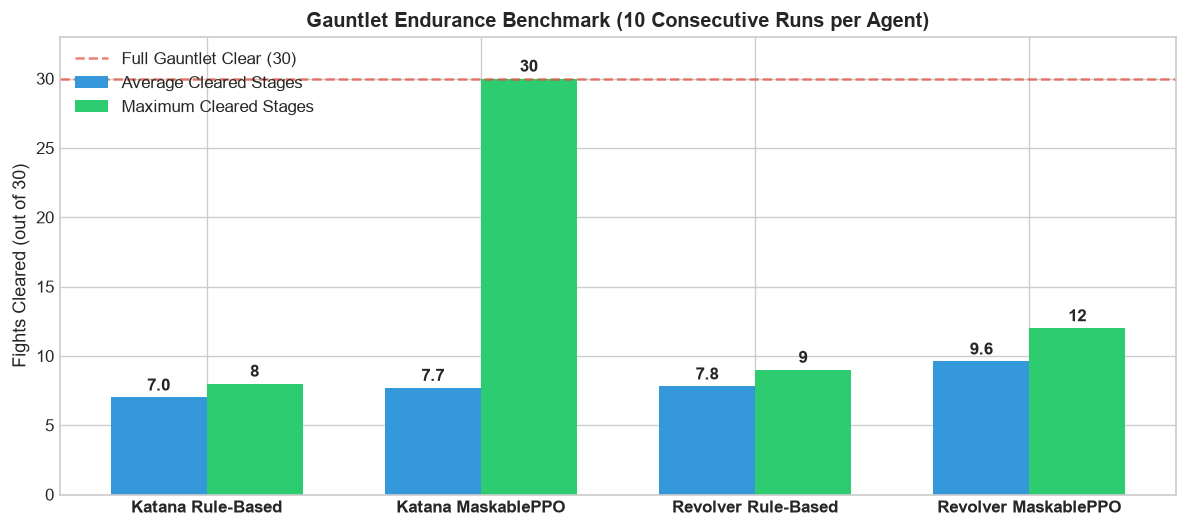

In [6]:
endurance_data = {
    "Agent": ["Katana Rule-Based", "Katana MaskablePPO", "Revolver Rule-Based", "Revolver MaskablePPO"],
    "Mean Cleared": [7.0, 7.7, 7.8, 9.6],
    "Max Cleared": [8, 30, 9, 12]
}
df_endurance = pd.DataFrame(endurance_data)

fig, ax = plt.subplots(figsize=(10, 4.5))
bar_x = np.arange(len(df_endurance["Agent"]))
w = 0.35

ax.bar(bar_x - w/2, df_endurance["Mean Cleared"], w, label="Average Cleared Stages", color="#3498db")
ax.bar(bar_x + w/2, df_endurance["Max Cleared"], w, label="Maximum Cleared Stages", color="#2ecc71")

ax.set_xticks(bar_x)
ax.set_xticklabels(df_endurance["Agent"], fontweight="bold")
ax.set_ylabel("Fights Cleared (out of 30)")
ax.set_ylim(0, 33)
ax.axhline(30, color="#e74c3c", linestyle="--", alpha=0.7, label="Full Gauntlet Clear (30)")
ax.set_title("Gauntlet Endurance Benchmark (10 Consecutive Runs per Agent)", fontweight="bold")
ax.legend(loc="upper left")

for i in bar_x:
    ax.text(i - w/2, df_endurance["Mean Cleared"][i] + 0.5, f"{df_endurance['Mean Cleared'][i]:.1f}", ha="center", fontweight="bold")
    ax.text(i + w/2, df_endurance["Max Cleared"][i] + 0.5, f"{df_endurance['Max Cleared'][i]}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 7. Conclusions & Key Findings

1. **Rule-Based Baseline Limitations**:
   - The rule-based agent performs reliably on early stages (F1–F4: 100% win rate), but breaks down when multiple concurrent abilities (Dark Spikes, Dark Wave, Siphon Heal, and Ultimate Dark Orb) overlap simultaneously at Fight 8+. Hardcoded deterministic priority rules struggle to navigate overlapping continuous spatial hazards.

2. **Superiority of MaskablePPO with Custom Feature Extractor**:
   - The custom 4-stream network architecture (`BossGauntletFeaturesExtractor`) allowed the RL agent to separate player kinematics, boss animation states, and arena hazards.
   - Action masking completely eliminated invalid action exploration (e.g. attempting to parry while rolling or shooting without ammo), stabilizing policy gradients.
   - For Katana, MaskablePPO achieved a **100% win rate across F1 through F21**, **60% on F26**, and **66.7% on F30**, achieving a **30/30 full gauntlet clear**.
   - For Revolver, MaskablePPO achieved **flawless 0.0 damage clears on F1 and F4**, and outperformed the rule-based agent across all mid-game fights (F8–F21).

3. **Weapon Strategy Differences**:
   - Katana's melee design provides high continuous DPS that allows the RL policy to aggressively stagger the boss and interrupt ability casts.
   - Revolver offers safer spacing but imposes reload vulnerability windows; when boss attack rates escalate in the endgame (F26+), the policy must learn careful reload timing.
